план решения
1. загрузила и изучила данные
2. отделила признаки от целевой переменной
3. разбила обучающую выборку на train/test, чтобы проверять модель
4. обработала пропуски в данных и привела признаки к одному масштабу
5. подготовила данные для pytorch
6. построила нейросеть
7. задала функцию потерь и оптимизатор
8. обучила модель
9. оценила качество модели по нескольким метрикам
10. построила график потерб
11. сделала финальные предсказания и сохранила их в нужном формате

In [16]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

открыла оба csv файла и посмотрела на них, сколько всего пациентов, колонок, сколько пациентов имеют диагноз 0, а сколько 1

диагноз 1 встречается намного реже, то есть классы несбалансированы

In [17]:
#загрузка данных

train_df = pd.read_csv("/content/train.csv")
test_df = pd.read_csv("/content/test_features.csv")

ID_COL = "patient_id"
TARGET_COL = "prediction"

print(f"Train: {train_df.shape[0]} объектов, {train_df.shape[1]} колонок")
print(f"Test: {test_df.shape[0]} объектов, {test_df.shape[1]} колонок")
print(f"Классы: 0 = {(train_df[TARGET_COL]==0).sum()}, 1 = {(train_df[TARGET_COL]==1).sum()}")

train_df.head()

Train: 800 объектов, 19 колонок
Test: 200 объектов, 18 колонок
Классы: 0 = 655, 1 = 145


,patient_id,Возраст,Пол_мужской,ИМТ,Окружность_талии_см,САД_мм_рт_ст,ДАД_мм_рт_ст,Пульсовое_давление,Глюкоза_натощак_ммоль_л,HbA1c_%,ЛПНП_ммоль_л,ЛПВП_ммоль_л,Триглицериды_ммоль_л,СКФ_мл_мин,Курение,Физическая_активность_мин_нед,prediction,Статус_глюкозы,Доклинический_риск
0,1,41,1,24.24,81.04,113.19,62.54,50.65,4.595,4.65,NaN,NaN,1.379,115.52,0,165.8,0,0,0
1,4,53,0,19.84,73.44,119.75,71.59,48.15,4.431,5.08,2.268,2.022,1.467,93.39,0,248.1,0,0,0
2,5,53,1,24.28,82.06,127.07,70.34,56.73,4.997,5.04,2.459,1.325,0.967,88.41,0,230.5,0,0,0
3,6,60,1,25.19,91.89,116.98,82.00,34.98,5.491,5.00,3.700,0.722,1.505,91.06,1,132.5,1,0,0
4,7,59,1,24.45,84.07,129.12,82.70,46.42,6.456,4.80,3.960,1.406,2.274,89.74,1,177.4,1,2,0


разбила таблицу на две части

X -  возраст, давление, холестерин и т.д. то, на основе чего модель будет делать предсказание


y - колонка prediction, то, что модель должна научиться предсказывать


In [18]:
# целевая переменная и признаки
feature_cols = [c for c in train_df.columns if c not in (ID_COL, TARGET_COL)]

X = train_df[feature_cols].values.astype(np.float32)
y = train_df[TARGET_COL].values.astype(np.float32).reshape(-1, 1)

X_test_final = test_df[feature_cols].values.astype(np.float32)
test_ids = test_df[ID_COL].values

print(f"Размер выборки: {X.shape[0]}, число признаков: {X.shape[1]}")

Размер выборки: 800, число признаков: 17


отложила 20% пациентов в сторону чтобы модель их вообще не видела во время обучения и чтобы потом проверить научилась ли модель находить закономерность

параметр stratify=y следит, чтобы в обеих частях сохранилась одинаковая пропорция
диагнозов 0 и 1

In [19]:
# разбиение на train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

в нескольких колонках данные не измерены и стоит пустое значение поэтому заполнила пропуски медианой посчитанной по обучающей выборке


привела все признаки к единому масштабу среднее = 0, разброс = 1, тк признаки измеряются в разных единицах и масштабах и если не привести всё к одному масштабу, нейросеть может решить, что признак с большими числами важнее


In [20]:
# обработка пропусков и нормализация признаков

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)
X_test_final = imputer.transform(X_test_final)

scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)
X_test_final = scaler_X.transform(X_test_final)

pytorch не умеет работать с pandas, ему нужен тензор, те  многомерный массив чисел
конвертировала данные и ответы в этот формат

In [21]:
# преобразование в тензоры PyTorch (многомерный массив чисел)
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

чтобы не подавать в нейросеть сразу все 640 обучающих пациентов, разрезала их на батчи по 32 человека

In [22]:
# создание DataLoader (подача батчами)
batch_size = 32
train_dataset = TensorDataset(X_train_t, y_train_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

построила саму сеть ffn, данные идут  слой за слоем

fc1- берёт все признаки пациента и превращает их в 64 числа, fc2- сжимает эти 64 числа до 32, fc3- сжимает 32 числа до одного числа, чем больше число, тем увереннее модель

во время обучения случайно выключает 20% нейронов (dropout 0.2) на каждом шаге, защита от переобучения

In [23]:
# определение модели FFN
class RiskFFN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = RiskFFN(X_train.shape[1]).to(device)

функция потерь loss — на каждом шаге модель
считает насколько сильно она ошиблась и подстраивается, чтобы ошибаться меньше
в следующий раз

так как диагноз 1 встречается редко, без pos_weight модель могла бы просто отвечать 0 и была бы права в большинстве случаев




In [24]:
# функция потерь и оптимизатор

n_pos = y_train.sum()
n_neg = len(y_train) - n_pos
pos_weight = torch.tensor([n_neg / n_pos], dtype=torch.float32).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(model.parameters(), lr=0.001)

train- модель по очереди смотрит на батчи из 32 пациентов, делает предсказание, сравнивает с правильным ответом и подстраивает свои внутренние параметры, чтобы в следующий раз ошибиться меньше


validation- после обучения на этой эпохе проверила модель на отложенных 20% пациентов но без обучения, просто посмотрела какая там ошибка

In [25]:
# цикл обучения
epochs = 150
train_losses, test_losses = [], []

for epoch in range(epochs):

    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)
    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            val_loss += loss.item() * X_batch.size(0)
    epoch_test_loss = val_loss / len(test_loader.dataset)
    test_losses.append(epoch_test_loss)

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{epochs} - Train Loss: {epoch_train_loss:.4f}, Test Loss: {epoch_test_loss:.4f}")

Epoch 20/150 - Train Loss: 0.1360, Test Loss: 0.3293
Epoch 40/150 - Train Loss: 0.0815, Test Loss: 0.4473
Epoch 60/150 - Train Loss: 0.0511, Test Loss: 0.6873
Epoch 80/150 - Train Loss: 0.0446, Test Loss: 0.7775
Epoch 100/150 - Train Loss: 0.0279, Test Loss: 0.8890
Epoch 120/150 - Train Loss: 0.0111, Test Loss: 0.9622
Epoch 140/150 - Train Loss: 0.0122, Test Loss: 1.2269


модель обучена, теперь измеряю, насколько хорошо она работает, разными способами

accuracy— доля правильных ответов в целом
precision— из всех, кому модель поставила диагноз 1, сколько реально были больны
recall— из всех реально больных, скольких модель нашла
f1-score— компромисс между precision и recall
roc-auc— насколько хорошо модель отличает класс 0 от класса 1


In [26]:
# метрики

model.eval()
y_pred_prob = []
y_true = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch)
        probs = torch.sigmoid(outputs)  # вероятность класса 1
        y_pred_prob.extend(probs.cpu().numpy().flatten())
        y_true.extend(y_batch.numpy().flatten())

y_pred_prob = np.array(y_pred_prob)
y_true = np.array(y_true)
y_pred_class = (y_pred_prob >= 0.5).astype(int)


print("Оценка на тестовой выборке:")
print(f"Accuracy:  {accuracy_score(y_true, y_pred_class):.4f}")
print(f"Precision: {precision_score(y_true, y_pred_class):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred_class):.4f}")
print(f"F1-score:  {f1_score(y_true, y_pred_class):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_true, y_pred_prob):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred_class))

Оценка на тестовой выборке:
Accuracy:  0.9437
Precision: 0.8846
Recall:    0.7931
F1-score:  0.8364
ROC-AUC:   0.9805

Confusion Matrix:
[[128   3]
 [  6  23]]


построила график того, как менялась ошибка на train и на test по мере обучения. если train-ошибка падает, а test-ошибка начинает
расти это сигнал переобучения

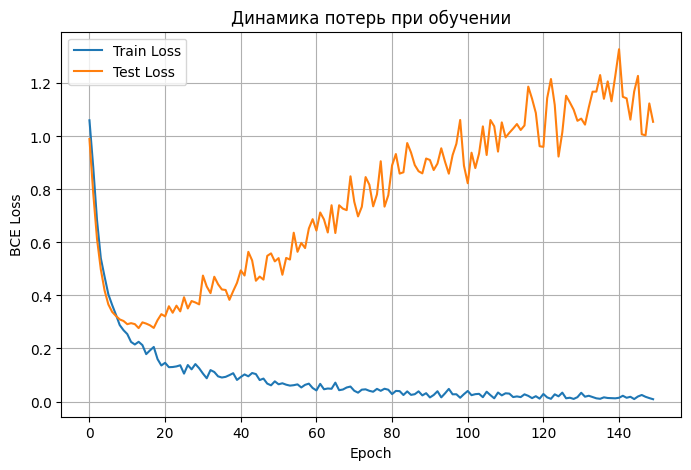

In [27]:
# график потерь
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('BCE Loss')
plt.title('Динамика потерь при обучении')
plt.legend()
plt.grid(True)
plt.show()

взяла 200 пациентов из test_features.csv, для которых не знаю правильного диагноза, прогнала их через обученную модель и получила предсказания

сохранила результат в файл outputs/task1_predictions.csv с двумя колонками patient_id и prediction

In [29]:
# предсказание на held-out выборке и сохранение
import os

X_test_final_t = torch.tensor(X_test_final, dtype=torch.float32)

model.eval()
with torch.no_grad():
    final_probs = torch.sigmoid(model(X_test_final_t.to(device))).cpu().numpy().flatten()

final_pred = (final_probs >= 0.5).astype(int)

submission = pd.DataFrame({
    "patient_id": test_ids,
    "prediction": final_pred
})

os.makedirs("outputs", exist_ok=True)
submission.to_csv("outputs/task1_predictions.csv", index=False)

print(f"Сохранено outputs/task1_predictions.csv, строк: {len(submission)}")
submission.head()

Сохранено outputs/task1_predictions.csv, строк: 200


,patient_id,prediction
0,2,0
1,3,0
2,8,0
3,18,0
4,19,0
